# Gradient forest: *P. guttatus*

Fit SNP-specific forests using the example VCF, sample coordinates and 19 bioclim rasters, then map environmental turnover.


## Install pyGF

The `pyGF` package is only available in my github repo, so the installation will need to be
'by hand'.

* Open a new terminal and `cd ~` to go to your home directory
* `git clone https://github.com/isaacovercast/pygf.git` to pull down this repository
* `pip install -e pygf` to install this package and all requirements
* Restart the kernel for this notebook w/ the 'circle arrow' button in the notebook toolbar
* Now you should be able to do the imports in the next cell

In [18]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from pygf import GradientForest, read_coordinates, read_vcf, sample_environment

## Read samples and genotypes

`read_coordinates` returns a GeoDataFrame from the headerless sample, longitude, latitude file. `read_vcf` returns an xarray Dataset of alternate-allele dosages (0, 1, 2), with missing calls as NaN.

Keep SNPs with call rate ≥ 80% and minor allele frequency ≥ 5%, then sample 256 across the file. `one_per_contig=True` keeps one eligible SNP per RAD contig; use `False` for whole-chromosome data. Set `max_variants=None` to keep all eligible SNPs. Plain and gzipped VCFs are supported.

`samples=sites` returns genotypes in coordinate-file order. Climate rows preserve the same order, so `sites`, `X` and `y` stay aligned.

In [2]:
sites = read_coordinates("/home/jovyan/vermivora_coords2.csv")

In [ ]:
path = "/home/jovyan/vermivora_genes.vcf"

with open(path) as f:
    header = None
    record_num = 0

    for line_num, line in enumerate(f, 1):
        if line.startswith("#CHROM"):
            header = line.rstrip("\r\n").split("\t")
            continue

        if line.startswith("#") or not line.strip():
            continue

        record_num += 1
        fields = line.rstrip("\r\n").split("\t")

        if len(fields) != len(header):
            print("Malformed record found!")
            print("Physical line:", line_num)
            print("Record number:", record_num)
            print("Expected:", len(header))
            print("Actual:", len(fields))
            print("Position:", fields[1] if len(fields) > 1 else "Unknown")
            print("Content:", repr(line))
            break

# remove problematic record
input_path = "/home/jovyan/vermivora_genes.vcf"
output_path = "/home/jovyan/vermivora_genes_clean.vcf"

with open(input_path) as infile, open(output_path, "w") as outfile:
    header = None
    removed = 0

    for line in infile:
        if line.startswith("#"):
            if line.startswith("#CHROM"):
                header = line.rstrip("\r\n").split("\t")

            outfile.write(line)
            continue

        if not line.strip():
            continue

        fields = line.rstrip("\r\n").split("\t")

        if len(fields) != len(header):
            removed += 1
            continue

        outfile.write(line)

print("Removed malformed records:", removed)
print("Clean VCF saved to:", output_path)

In [6]:
genotypes

<xarray.Dataset> Size: 97kB
Dimensions:    (sample: 24, variant: 256)
Coordinates:
  * sample     (sample) <U3 288B '701' '703' '704' '705' ... '741' '742' '743'
  * variant    (variant) <U37 38kB 'scaffold1.1_size22943089:358977:C:T' ... ...
Data variables:
    dosage     (sample, variant) float32 25kB 0.0 0.0 0.0 nan ... 0.0 0.0 0.0
    chrom      (variant) <U24 25kB 'scaffold1.1_size22943089' ... 'scaffold2....
    position   (variant) int64 2kB 358977 800221 1115140 ... 2651249 2832540
    vcf_id     (variant) <U1 1kB '.' '.' '.' '.' '.' '.' ... '.' '.' '.' '.' '.'
    ref        (variant) <U1 1kB 'C' 'A' 'C' 'A' 'T' 'G' ... 'A' 'G' 'A' 'A' 'C'
    alt        (variant) <U1 1kB 'T' 'C' 'T' 'C' 'G' 'T' ... 'C' 'A' 'G' 'C' 'G'
    call_rate  (variant) float64 2kB 0.8333 0.9167 0.875 ... 0.8333 0.9167
    maf        (variant) float64 2kB 0.125 0.1136 0.1429 ... 0.2727 0.1 0.1136
Attributes:
    source:             /home/jovyan/vermivora_genes_clean.vcf
    records_scanned:    241035
    eligible_variants:  104407
    min_call_rate:      0.8
    min_maf:            0.05
    one_per_contig:     0
    dosage_encoding:    alternate-allele count (0, 1, 2); missing=NaN

In [17]:
genotypes = read_vcf(
    "/home/jovyan/vermivora_genes_clean.vcf",
    samples=sites,
    min_call_rate=0.8,
    min_maf=0.05,
    one_per_contig=False,
    max_variants=256,
    random_state=42,
)

NameError: name 'gpd' is not defined

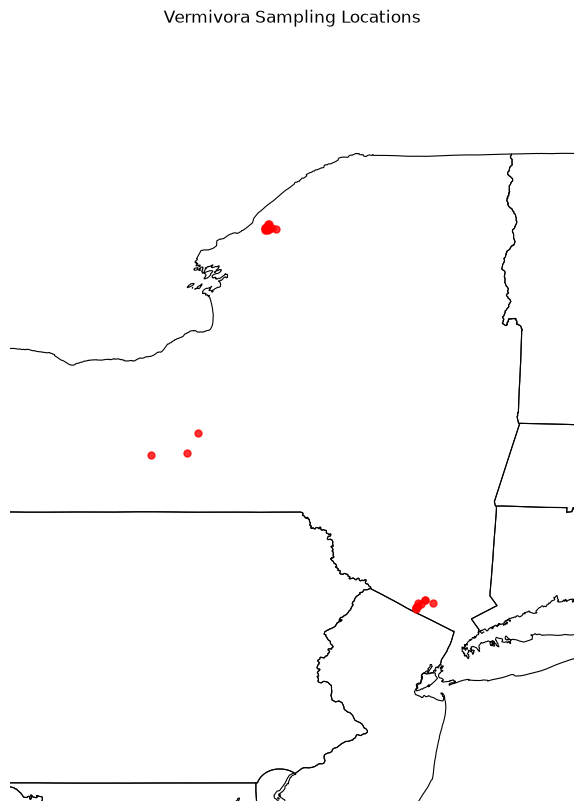

In [23]:
states = gpd.read_file(
    "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_state_500k.zip"
)

# Match coordinate reference systems
states = states.to_crs(sites.crs)

# Plot sites
ax = sites.plot(
    figsize=(12, 10),
    color="red",
    markersize=25,
    alpha=0.8,
    zorder=2
)

# State outlines
states.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8,
    zorder=1
)

# Zoom to Vermivora sampling points with padding
xmin, ymin, xmax, ymax = sites.total_bounds
xpad = (xmax - xmin) * 0.5
ypad = (ymax - ymin) * 0.5

ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

ax.set_title("Vermivora Sampling Locations")
ax.set_axis_off()

plt.show()

## Sample climate

`sample_environment` takes the bioclim directory, opens a bounding box around the sites with 20% of its width/height added on each side, and extracts native-resolution values in coordinate-file order. It reprojects sites to the raster CRS and closes the rasters after sampling. Use `variables=["bio1", "bio12"]` to select layers or `buffer=0.1` for a smaller region.

Missing climate values remain NaN. `drop_missing=True` removes incomplete rows; if used, align the other inputs to those remaining IDs once before fitting. The example retains all 36 sites.

In [7]:
X = sample_environment("/home/jovyan/shared/bioclim", sites)
y = genotypes.dosage.to_pandas()
X.head()

,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
701,9.306167,11.059000,30.675137,915.158997,27.559999,-8.492,36.051998,18.180000,-2.254667,20.365334,-2.254667,1301.0,123.0,82.0,10.269712,352.0,281.0,338.0,281.0
703,9.167666,10.721334,30.095816,912.005920,27.200001,-8.424,35.624001,17.994667,-2.340000,20.198668,-2.340000,1324.0,125.0,84.0,9.879003,354.0,288.0,341.0,288.0
704,9.306167,11.059000,30.675137,915.158997,27.559999,-8.492,36.051998,18.180000,-2.254667,20.365334,-2.254667,1301.0,123.0,82.0,10.269712,352.0,281.0,338.0,281.0
705,9.306167,11.059000,30.675137,915.158997,27.559999,-8.492,36.051998,18.180000,-2.254667,20.365334,-2.254667,1301.0,123.0,82.0,10.269712,352.0,281.0,338.0,281.0
706,9.283334,11.062667,30.763811,911.382996,27.472000,-8.488,35.959999,18.090000,-2.226667,20.288000,-2.226667,1310.0,123.0,83.0,10.069532,353.0,284.0,340.0,284.0


In [8]:
len(y.columns) # number of snps retained

256

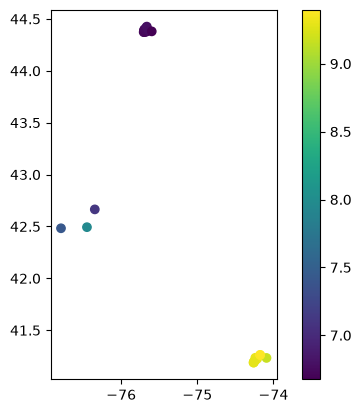

In [9]:
sites.plot(column=X.bio1, legend=True);

## Fit and inspect

Each SNP uses its observed genotypes. Only responses with positive out-of-bag (OOB) R² and permutation importance contribute to turnover.

`max_level=2` uses approximate conditional permutations for correlated predictors; `max_level=0` gives marginal permutations. `corr_threshold` sets the correlation cutoff. Other options control tree size (`max_features`, `min_samples_leaf`, `max_depth`), curve resolution (`n_bins`), permutation repeats (`n_permutations`), minimum skill (`min_oob_r2`), density correction (`density_correction`) and tree parallelism (`n_jobs`).

In [10]:
gf = GradientForest(
    n_estimators=100, max_level=2, random_state=42, keep_response_curves=True,
).fit(X, y)
gf.response_scores_.sort_values("oob_r2", ascending=False).head()

,n_observed,oob_r2,oob_coverage,retained,reason
response,,,,,
scaffold1.1_size22943089:8170116:G:A,21,0.429044,1.0,True,retained
scaffold2.1_size20527936:1939412:T:G,20,0.301679,1.0,True,retained
scaffold1.1_size22943089:9948816:A:G,21,0.238846,1.0,True,retained
scaffold1.1_size22943089:1586550:C:T,21,0.212317,1.0,True,retained
scaffold1.1_size22943089:3155583:C:T,20,0.207005,1.0,True,retained


`response_scores_` records OOB skill and inclusion for every SNP; `oob_predictions_` holds its OOB predictions. `permutation_importances_` contains raw MSE increases and `response_importances_` contains allocated R². Set `keep_forests=True` to retain fitted trees in `forests_`.

`importance_` ranks predictors by mean allocated R²; `feature_importances_` contains the same values in input order.

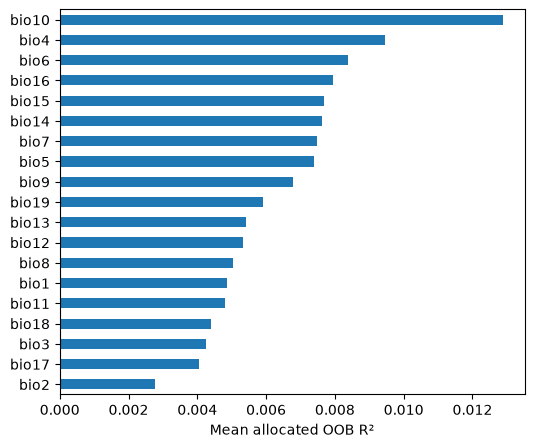

In [11]:
gf.importance_.sort_values().plot.barh(figsize=(6, 5), xlabel="Mean allocated OOB R²");

## Turnover curves and transformed samples

`turnover_` contains a cumulative curve for each predictor. Steep sections indicate rapid turnover; endpoints give predictor importance. `transform` returns these turnover coordinates, preserving sample IDs. `predict` is an alias; `fit_transform(X, y)` combines fitting and transformation.

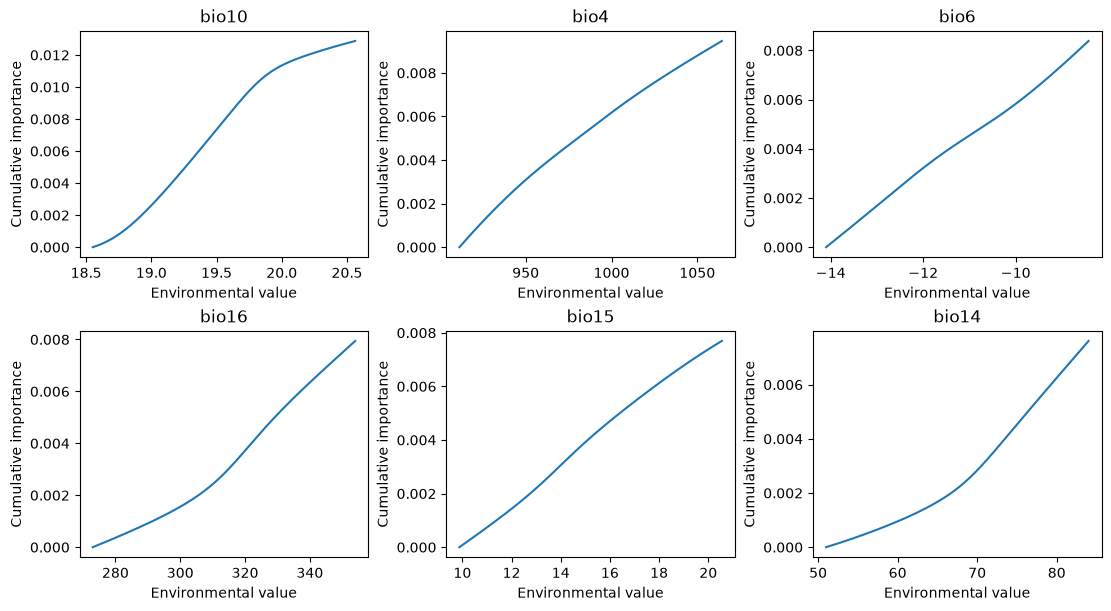

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
for ax, name in zip(axes.flat, gf.importance_.head(6).index):
    curve = gf.turnover_[name]
    ax.plot(curve.value, curve.cumulative_importance)
    ax.set(title=name, xlabel="Environmental value", ylabel="Cumulative importance")
plt.show()

In [13]:
turnover = gf.transform(X)
turnover.head()

,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
701,0.004693,0.002660,0.004141,0.000336,0.006976,0.008266,0.000674,0.004607,0.006703,0.012429,0.004762,0.004892,0.005292,0.006933,0.000254,0.007717,0.003807,0.004205,0.005517
703,0.004432,0.000939,0.003388,0.000056,0.006087,0.008385,0.000000,0.004535,0.006501,0.012002,0.004658,0.005334,0.005416,0.007612,0.000000,0.007943,0.004062,0.004389,0.005908
704,0.004693,0.002660,0.004141,0.000336,0.006976,0.008266,0.000674,0.004607,0.006703,0.012429,0.004762,0.004892,0.005292,0.006933,0.000254,0.007717,0.003807,0.004205,0.005517
705,0.004693,0.002660,0.004141,0.000336,0.006976,0.008266,0.000674,0.004607,0.006703,0.012429,0.004762,0.004892,0.005292,0.006933,0.000254,0.007717,0.003807,0.004205,0.005517
706,0.004651,0.002682,0.004261,0.000000,0.006781,0.008273,0.000529,0.004572,0.006769,0.012238,0.004796,0.005065,0.005292,0.007273,0.000124,0.007830,0.003917,0.004328,0.005686


## Map turnover

`plot_turnover()` uses the directory and sites remembered from `sample_environment`, opens the same buffered region, transforms it, and overlays the sites. It defaults to the most important predictor; pass a name such as `"bio1"` to choose another. Directory maps use every fourth cell by default (`stride=1` keeps native resolution).

The result exposes `.figure`, `.ax` and a computed xarray `.turnover` Dataset for export. `transform_raster` remains available for custom xarray grids; missing pixels are masked and values outside training ranges are clamped.

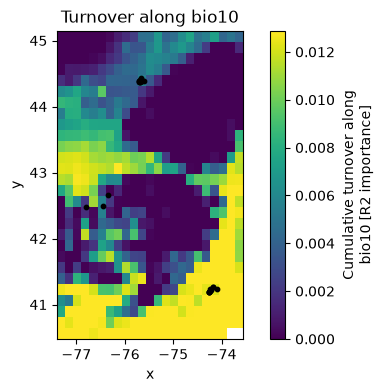

In [14]:
turnover_map = gf.plot_turnover()  # Or gf.plot_turnover("bio1"). by default it does the most important predictor.

## Spatial turnover and environmental biplots

The map and biplot share colours from the first three PCs of GF-transformed environments. Pass the bioclim directory; site bounds, the 20% buffer and downsampling are handled internally. PCA uses the resulting region without standardizing predictors, so GF importance weights are preserved. Labelled arrows show the largest environmental covariance loadings in PC1/2: direction indicates increasing values and relative length indicates contribution to the displayed pattern.

`response=None` uses all contributing SNPs. Pass a SNP name for its own turnover curves (requires `keep_response_curves=True` when fitting). `n_vectors` controls labelled arrows; `label_sites=True` adds sample IDs; `inset=True` places the biplot inside the map. Omit `environment` for a PCA of sample locations alone.

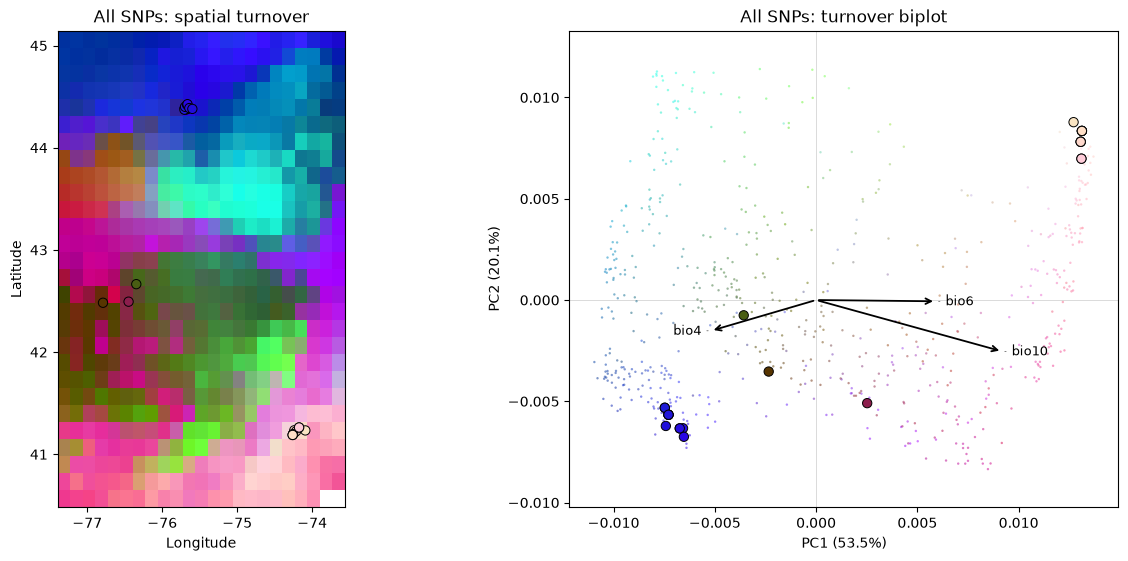

In [15]:
biplot = gf.plot_biplot(X, sites, environment="/home/jovyan/shared/bioclim", n_vectors=3)

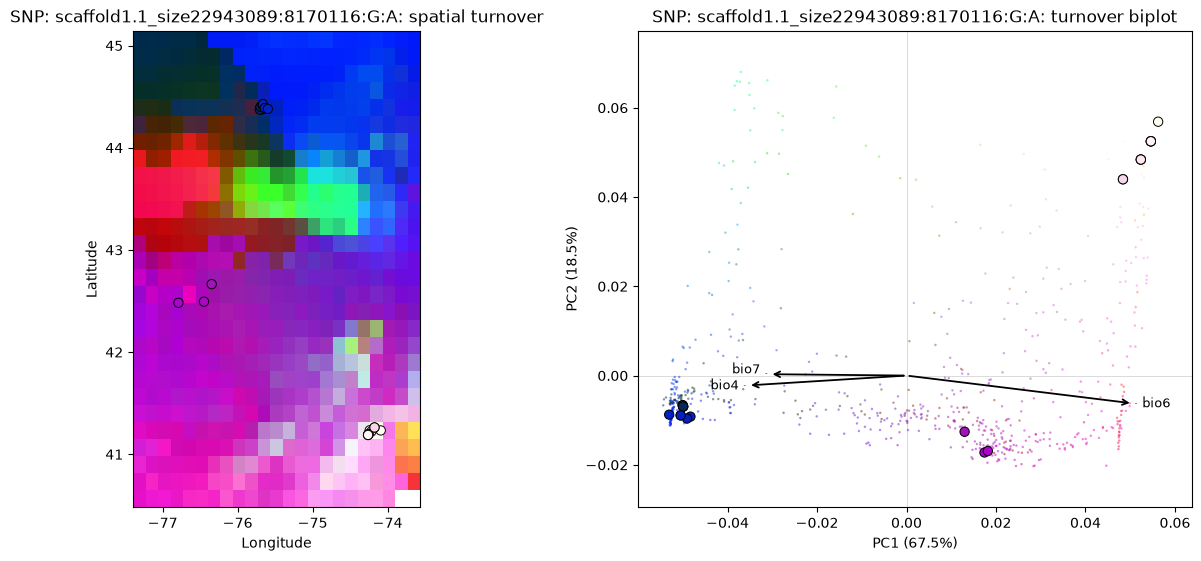

In [16]:
snp = gf.response_scores_.oob_r2.idxmax() # plots snp with largest oob r2
snp_biplot = gf.plot_biplot(X, sites, environment="/home/jovyan/shared/bioclim", response=snp, n_vectors=3)

`biplot.scores`, `.vectors` and `.colors` contain the numerical results; `.rgb` is the georeferenced map colour array. Each SNP has its own PCA/colour scale. These plots summarize predicted turnover, not predicted allele frequencies. This example uses individuals; for population-level composition, fit population allele frequencies against population-level environments and supply population locations.

## Export

Save diagnostics, sample coordinates, curves and a GeoTIFF with one named band per predictor.

In [27]:
Path("outputs").mkdir(exist_ok=True)
gf.response_scores_.to_csv("outputs/snp_oob_scores.csv")
gf.importance_.to_csv("outputs/predictor_importance.csv")
turnover.to_csv("outputs/sample_turnover.csv")
pd.concat(gf.turnover_, names=["predictor", "bin"]).to_csv("outputs/turnover_curves.csv")

bands = turnover_map.turnover.to_array("band").rio.write_nodata(np.nan)
bands.attrs["long_name"] = tuple(X.columns)
bands.rio.to_raster("outputs/genomic_turnover.tif", compress="deflate", dtype="float32")
turnover_map.figure.savefig("outputs/turnover_map.png", dpi=150, bbox_inches="tight")
biplot.figure.savefig("outputs/turnover_biplot.png", dpi=150, bbox_inches="tight")
snp_biplot.figure.savefig("outputs/snp_biplot.png", dpi=150, bbox_inches="tight")

These are individual genotype responses, not population allele frequencies. OOB skill and turnover alone do not establish adaptation or spatial transfer accuracy. Conditional permutations and smoothing differ from R gradientForest; see the [README](../README.md) for method details and [Ellis et al. (2012)](https://doi.org/10.1890/11-0252.1) for the original method.